Download the dataset from https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic onto a google drive folder. This is the dataset on which the prototype of the model is built and tested. <br><br>
The below scripts were run on Google colab via VS Code IDE


In [1]:
import html
from IPython.display import display, HTML

In [2]:
import os
os.makedirs('plots', exist_ok=True)


In [3]:
import glob, time
from google.colab import files

### Download data and unzip

In [4]:
import gdown, zipfile, os

url = "https://drive.google.com/file/d/13i9CSJVmjX1GdUzMLZU7HC07p-EDC2sf/view?usp=drive_link"
zip_path = "dataset_prototype.zip"
DATA_DIR = "extracted"

gdown.download(url, zip_path, quiet=False, fuzzy=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(DATA_DIR)

print(os.listdir(DATA_DIR))   # should show ['wdbc.data', 'wdbc.names']


Downloading...
From: https://drive.google.com/uc?id=13i9CSJVmjX1GdUzMLZU7HC07p-EDC2sf
To: /content/dataset_prototype.zip
100%|██████████| 51.3k/51.3k [00:00<00:00, 25.4MB/s]

['wdbc.names', 'wdbc.data']


#### Read dataset description

In [5]:
text = open(f"{DATA_DIR}/wdbc.names").read()
display(HTML(f"<pre>{html.escape(text)}</pre>"))


#### Relevant papers
| # | Paper | What it's about | Link | Free full text? |
|---|-------|-----------------|------|-----------------|
| 1 | Street, Wolberg & Mangasarian (1993). *Nuclear feature extraction for breast tumor diagnosis.* SPIE vol. 1905, pp. 861–870 | How the 30 features were measured from cell images (dataset origin) | https://www.semanticscholar.org/paper/Nuclear-feature-extraction-for-breast-tumor-Street-Wolberg/53f0fbb425bc14468eb3bf96b2e1d41ba8087f36 | Check Semantic Scholar for PDF |
| 2 | Bennett (1992). *Decision Tree Construction Via Linear Programming.* Proc. 4th Midwest AI & Cog. Sci. Conf., pp. 97–101 | MSM-T: the tree of cuts (1–3 separating planes) | https://minds.wisconsin.edu/handle/1793/59564 | Yes (UW tech report) |
| 3 | Bennett & Mangasarian (1992). *Robust Linear Programming Discrimination of Two Linearly Inseparable Sets.* Optim. Methods & Software 1, pp. 23–34 | How each separating plane is placed (minimizes errors) | https://minds.wisconsin.edu/handle/1793/59538 | Yes (UW tech report) |
| 4 | Wolberg, Street & Mangasarian (1994). *Machine learning techniques to diagnose breast cancer from image-processed nuclear features of fine needle aspirates.* Cancer Letters 77, pp. 163–171 | Clinical results: 97.5% accuracy on 569 patients | https://doi.org/10.1016/0304-3835(94)90099-X | Paywalled |
| 5 | Wolberg, Street & Mangasarian (1995). *Image analysis and machine learning applied to breast cancer diagnosis and prognosis.* Anal. Quant. Cytol. Histol. 17(2), pp. 77–87 | Diagnosis + prognosis follow-up | https://www.researchgate.net/publication/15587278_Image_analysis_and_machine_learning_applied_to_breast_cancer_diagnosis_and_prognosis | Maybe (ResearchGate) |
| 6 | Wolberg, Street, Heisey & Mangasarian (1995). *Computerized breast cancer diagnosis and prognosis from fine-needle aspirates.* Archives of Surgery 130, pp. 511–516 | Clinical paper for surgeons | https://jamanetwork.com/journals/jamasurgery/article-abstract/596210 | Paywalled |
| — | UCI dataset page: Breast Cancer Wisconsin (Diagnostic) | Official dataset page + description | https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic | Yes |


### load the dataset

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns

base = ['radius','texture','perimeter','area','smoothness','compactness',
        'concavity','concave_points','symmetry','fractal_dimension']
cols = ['id','diagnosis'] + [f'{f}_{s}' for s in ['mean','se','worst'] for f in base]

df = pd.read_csv(f"{DATA_DIR}/wdbc.data", header=None, names=cols)
df.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Check if the loaded dataset matches the dataset description


In [7]:
print("Shape:", df.shape)                        # expect (569, 32)
print("Missing values:", df.isna().sum().sum())  # expect 0
print("Duplicate IDs:", df.id.duplicated().sum())
print(df.diagnosis.value_counts())               # M = malignant, B = benign
df.describe().T


Shape: (569, 32)
Missing values: 0
Duplicate IDs: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave_points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


### Summarize the dataset
The summary includes the following values:<br>
count, mean, standard deviation(sd), max, min, co-efficient of variation (CV = Standard Deviation/Mean), 25th, 50th (median), 75th percentiles, and number of missing values

In [8]:
feat_cols = df.columns[2:]   # the 30 numeric features (skip id and diagnosis)

summary = df[feat_cols].describe().T                     # count, mean, std, min, 25%, 50%, 75%, max
summary['cv'] = summary['std'] / summary['mean']        # coefficient of variation
summary['missing'] = df[feat_cols].isna().sum()         # missing values per column
summary.index.name = 'feature'

summary.to_csv('dataset_summary.csv')

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs:", df.id.duplicated().sum())
print(df.diagnosis.value_counts())
summary


Shape: (569, 32)
Missing values: 0
Duplicate IDs: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max,cv,missing
feature,,,,,,,,,,
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,0.249450,0
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,0.222971,0
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,0.264208,0
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,0.537364,0
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.145954,0
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,0.506155,0
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,0.897753,0
concave_points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,0.793204,0
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.151325,0


In [9]:
summary.shape

(30, 10)

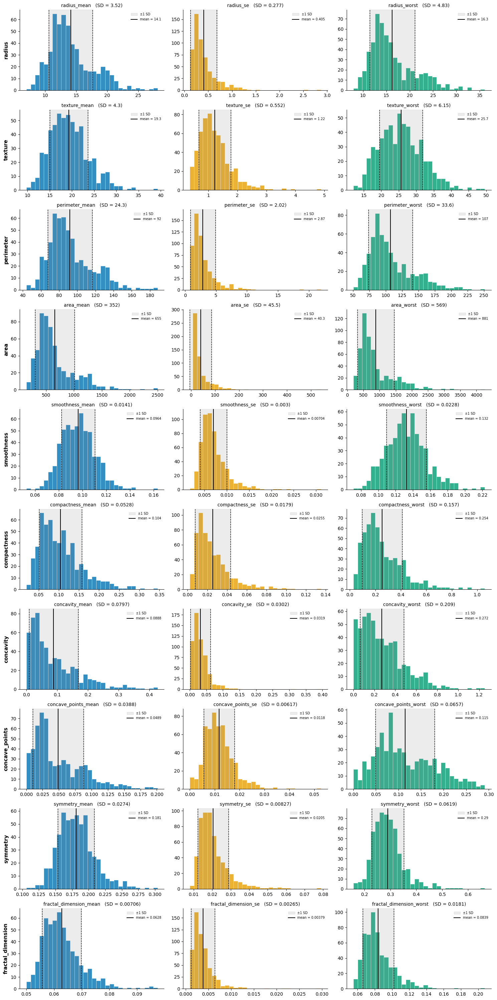

In [10]:

import matplotlib.pyplot as plt

versions = ['mean', 'se', 'worst']
colors = {'mean': '#0072B2', 'se': '#E69F00', 'worst': '#009E73'}   # fixed colour per version

fig, axes = plt.subplots(len(base), 3, figsize=(15, 3 * len(base)))

for i, feat in enumerate(base):
    for j, v in enumerate(versions):
        ax = axes[i, j]
        col = f'{feat}_{v}'
        x = df[col]
        mu, sd = x.mean(), x.std()

        ax.hist(x, bins=30, color=colors[v], alpha=0.8, edgecolor='white', linewidth=0.5)

        # mean and ±1 SD
        ax.axvspan(mu - sd, mu + sd, color='grey', alpha=0.15, label='±1 SD')
        ax.axvline(mu, color='black', linewidth=1.5, label=f'mean = {mu:.3g}')
        ax.axvline(mu - sd, color='black', linewidth=1, linestyle='--')
        ax.axvline(mu + sd, color='black', linewidth=1, linestyle='--')

        ax.set_title(f'{col}   (SD = {sd:.3g})', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(fontsize=7, frameon=False)
        if j == 0:
            ax.set_ylabel(feat, fontsize=11, fontweight='bold')

plt.tight_layout()
fig.savefig('plots/01_all_features.png', dpi=200, bbox_inches='tight')
plt.show()

Segregate the dataset into benign and malignant values and visuzlise the distribution

Density distributions

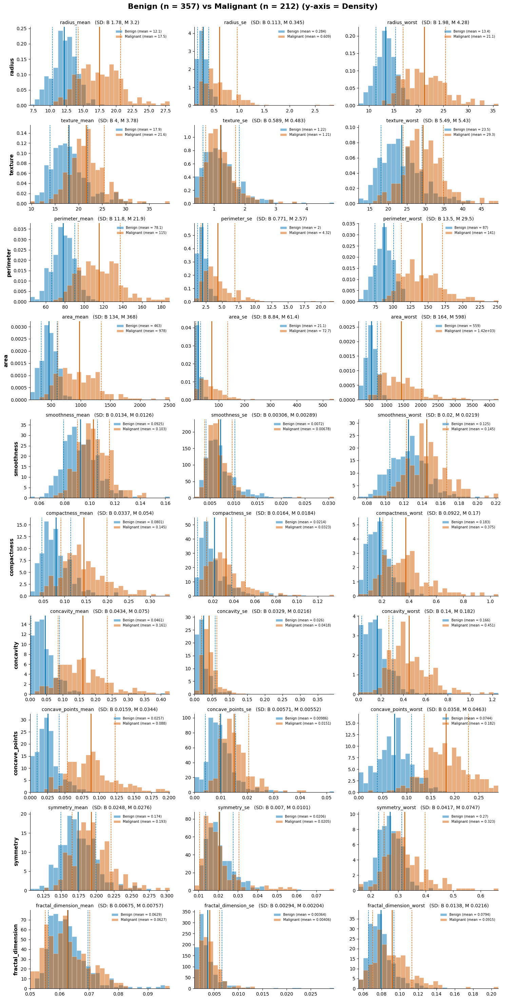

In [11]:
import matplotlib.pyplot as plt
import numpy as np

versions = ['mean', 'se', 'worst']
colors = {'B': '#0072B2', 'M': '#D55E00'}   # fixed colour per diagnosis
labels = {'B': 'Benign', 'M': 'Malignant'}
n = df.diagnosis.value_counts()

fig, axes = plt.subplots(len(base), 3, figsize=(15, 3 * len(base)))
fig.suptitle(f"Benign (n = {n['B']}) vs Malignant (n = {n['M']}) (y-axis = Density)", fontsize=16, fontweight='bold')

for i, feat in enumerate(base):
    for j, v in enumerate(versions):
        ax = axes[i, j]
        col = f'{feat}_{v}'

        # same bins for B and M, taken from the full column, so the two are directly comparable
        bins = np.linspace(df[col].min(), df[col].max(), 31)

        sds = []
        for diag in ['B', 'M']:
            x = df.loc[df.diagnosis == diag, col]
            mu, sd = x.mean(), x.std()
            sds.append(f'{diag} {sd:.3g}')

            # density=True scales each group to area 1, so B (n=357) and M (n=212) are comparable
            ax.hist(x, bins=bins, density=True, color=colors[diag], alpha=0.5, edgecolor='white', linewidth=0.5,
                    label=f'{labels[diag]} (mean = {mu:.3g})')

            # mean (solid) and ±1 SD (dashed), in the diagnosis colour
            ax.axvline(mu, color=colors[diag], linewidth=1.8)
            ax.axvline(mu - sd, color=colors[diag], linewidth=1, linestyle='--')
            ax.axvline(mu + sd, color=colors[diag], linewidth=1, linestyle='--')

        ax.set_xlim(df[col].min(), df[col].max())
        ax.set_title(f'{col}   (SD: {", ".join(sds)})', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(fontsize=7, frameon=False)
        if j == 0:
            ax.set_ylabel(feat, fontsize=11, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig('plots/02_density_benign_vs_malignant.png', dpi=200, bbox_inches='tight')
plt.show()


For counts distribution

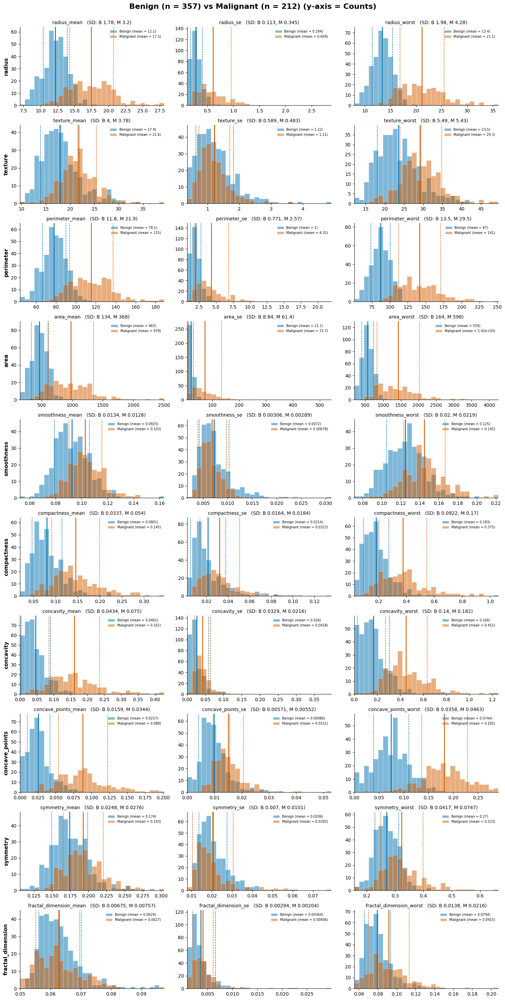

In [12]:
import matplotlib.pyplot as plt
import numpy as np

versions = ['mean', 'se', 'worst']
colors = {'B': '#0072B2', 'M': '#D55E00'}   # fixed colour per diagnosis
labels = {'B': 'Benign', 'M': 'Malignant'}
n = df.diagnosis.value_counts()

fig, axes = plt.subplots(len(base), 3, figsize=(15, 3 * len(base)))
fig.suptitle(f"Benign (n = {n['B']}) vs Malignant (n = {n['M']}) (y-axis = Counts)", fontsize=16, fontweight='bold')

for i, feat in enumerate(base):
    for j, v in enumerate(versions):
        ax = axes[i, j]
        col = f'{feat}_{v}'

        # same bins for B and M, taken from the full column, so the two are directly comparable
        bins = np.linspace(df[col].min(), df[col].max(), 31)

        sds = []
        for diag in ['B', 'M']:
            x = df.loc[df.diagnosis == diag, col]
            mu, sd = x.mean(), x.std()
            sds.append(f'{diag} {sd:.3g}')

            # density=True scales each group to area 1, so B (n=357) and M (n=212) are comparable
            ax.hist(x, bins=bins, density=False, color=colors[diag], alpha=0.5, edgecolor='white', linewidth=0.5,
                    label=f'{labels[diag]} (mean = {mu:.3g})')

            # mean (solid) and ±1 SD (dashed), in the diagnosis colour
            ax.axvline(mu, color=colors[diag], linewidth=1.8)
            ax.axvline(mu - sd, color=colors[diag], linewidth=1, linestyle='--')
            ax.axvline(mu + sd, color=colors[diag], linewidth=1, linestyle='--')

        ax.set_xlim(df[col].min(), df[col].max())
        ax.set_title(f'{col}   (SD: {", ".join(sds)})', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(fontsize=7, frameon=False)
        if j == 0:
            ax.set_ylabel(feat, fontsize=11, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig('plots/03_counts_benign_vs_malignant.png', dpi=200, bbox_inches='tight')
plt.show()


Observations from the above distributions:<br>
`area_se`,`fractal_dimension_se`, and `concavity_se` the distribution is skewed. So most likely they need to be log-transformed when used in the model training i.e if the model assumes a normal distribution? (logistic regression?)

### Evaluate the differences between the features for malignant and benign to see which features separates the class well

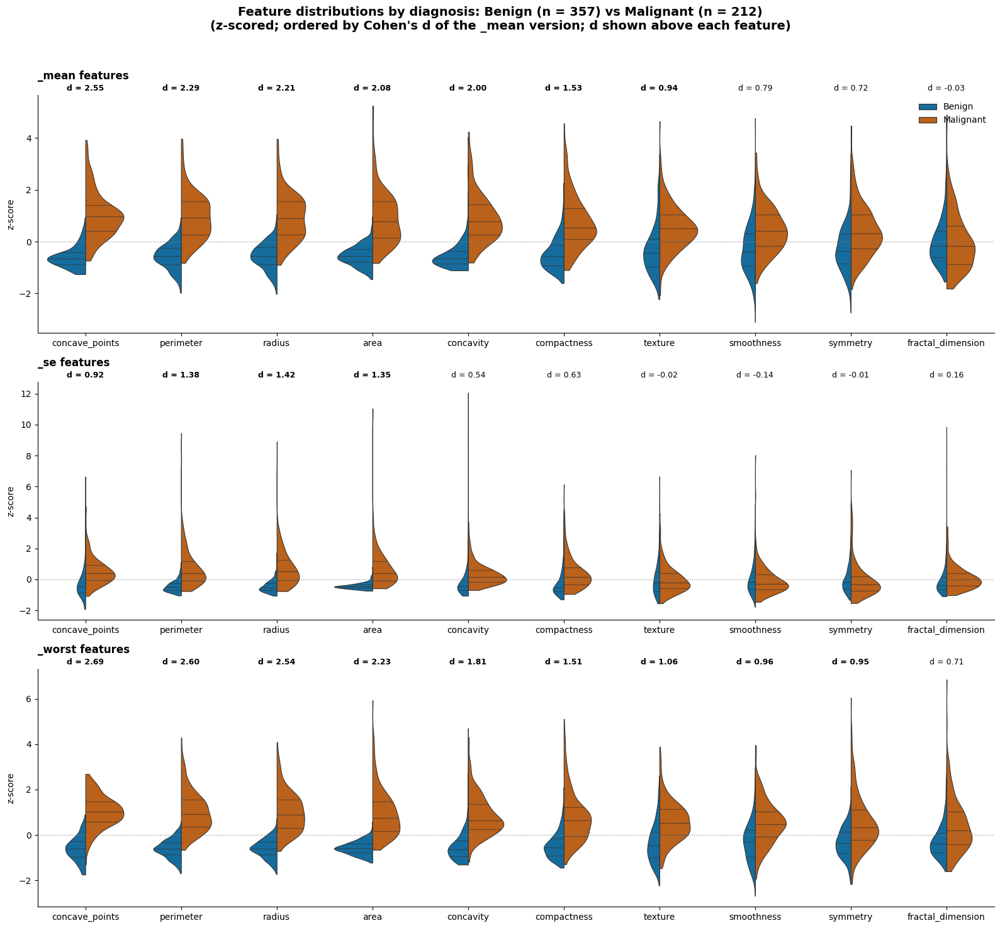

In [13]:


versions = ['mean', 'se', 'worst']
colors = {'B': '#0072B2', 'M': '#D55E00'}   # same diagnosis colours as plots 02/03
labels = {'B': 'Benign', 'M': 'Malignant'}
n = df.diagnosis.value_counts()

def cohens_d(col):
    """(malignant mean - benign mean) / pooled SD; |d| > 0.8 = large, < 0.2 = negligible"""
    b = df.loc[df.diagnosis == 'B', col]
    m = df.loc[df.diagnosis == 'M', col]
    pooled = np.sqrt(((len(b) - 1) * b.var() + (len(m) - 1) * m.var()) / (len(b) + len(m) - 2))
    return (m.mean() - b.mean()) / pooled

# order features by how well the _mean version separates the classes (best on the left)
order = sorted(base, key=lambda f: abs(cohens_d(f'{f}_mean')), reverse=True)

# z-score every feature so area (~1000s) and fractal_dimension (~0.06) fit on one axis
z = (df[feat_cols] - df[feat_cols].mean()) / df[feat_cols].std()
z['diagnosis'] = df.diagnosis

fig, axes = plt.subplots(3, 1, figsize=(16, 15))
fig.suptitle(f"Feature distributions by diagnosis: Benign (n = {n['B']}) vs Malignant (n = {n['M']})\n"
             f"(z-scored; ordered by Cohen's d of the _mean version; d shown above each feature)",
             fontsize=14, fontweight='bold')

for ax, v in zip(axes, versions):
    cols = [f'{f}_{v}' for f in order]
    long = z.melt(id_vars='diagnosis', value_vars=cols, var_name='feature', value_name='z')
    long['feature'] = long['feature'].str.removesuffix(f'_{v}')

    # split violin: benign on the left half, malignant on the right; dashed lines = quartiles
    sns.violinplot(data=long, x='feature', y='z', hue='diagnosis', order=order, hue_order=['B', 'M'],
                   split=True, inner='quart', cut=0, palette=colors, linewidth=0.8, ax=ax)

    # Cohen's d above each feature (x in data coords, y just above the top of the axis)
    for i, f in enumerate(order):
        d = cohens_d(f'{f}_{v}')
        ax.text(i, 1.01, f'd = {d:.2f}', transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=9, fontweight='bold' if abs(d) > 0.8 else 'normal')

    ax.axhline(0, color='grey', linewidth=0.8, linestyle=':')
    ax.set_title(f'_{v} features', loc='left', fontsize=12, fontweight='bold', pad=18)
    ax.set_xlabel('')
    ax.set_ylabel('z-score')
    ax.spines[['top', 'right']].set_visible(False)

    if v == 'mean':
        handles, _ = ax.get_legend_handles_labels()
        ax.legend(handles, [labels['B'], labels['M']], frameon=False, loc='upper right')
    else:
        ax.get_legend().remove()

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig('plots/04_violin_benign_vs_malignant.png', dpi=200, bbox_inches='tight')
plt.show()


A feature separates the classes well when the two halves of its violin sit at different heights and barely overlap, and its |d| is large (shown in bold). When the halves sit at nearly the same height, the feature tells the classes apart poorly.<br>
**Features that best separate Benign vs Malignant (violin plots / Cohen's d)**

**Best (d ≥ 2, little overlap)**
1. concave_points_worst (2.69)
2. perimeter_worst (2.60)
3. concave_points_mean (2.55)
4. radius_worst (2.54)
5. perimeter_mean (2.29)
6. area_worst (2.23)
7. radius_mean (2.21)
8. area_mean (2.08)
9. concavity_mean (2.00)

**Good (d ≈ 1.4–1.8)**
- concavity_worst (1.81)
- compactness_mean (1.53)
- compactness_worst (1.51)
- radius_se (1.42)
- perimeter_se (1.38)
- area_se (1.35)

**Weak, heavy overlap (d ≈ 0.7–1.1)**
- texture, smoothness, symmetry (_mean and _worst)
- concave_points_se
- fractal_dimension_worst

**Not useful alone (d ≈ 0)**
- fractal_dimension_mean
- texture_se, smoothness_se, symmetry_se, fractal_dimension_se

**Summary**
- The classes are described best by concave points and size (perimeter, radius, area), especially the _worst versions, followed by concavity and compactness.
- Caveat: perimeter, radius and area are nearly the same measurement (r ≈ 0.99), so the top of the list is really two kinds of information:
  - Shape irregularity: concave points, concavity
  - Size: perimeter, radius, area
- A small, non-redundant set: concave_points_worst + one size feature (e.g. perimeter_worst or area_worst), optionally + texture_worst, which adds different information despite its lower d.

### Correlation heatmap to identify which features carry the same information. 
Important to decide which features to pick for a model

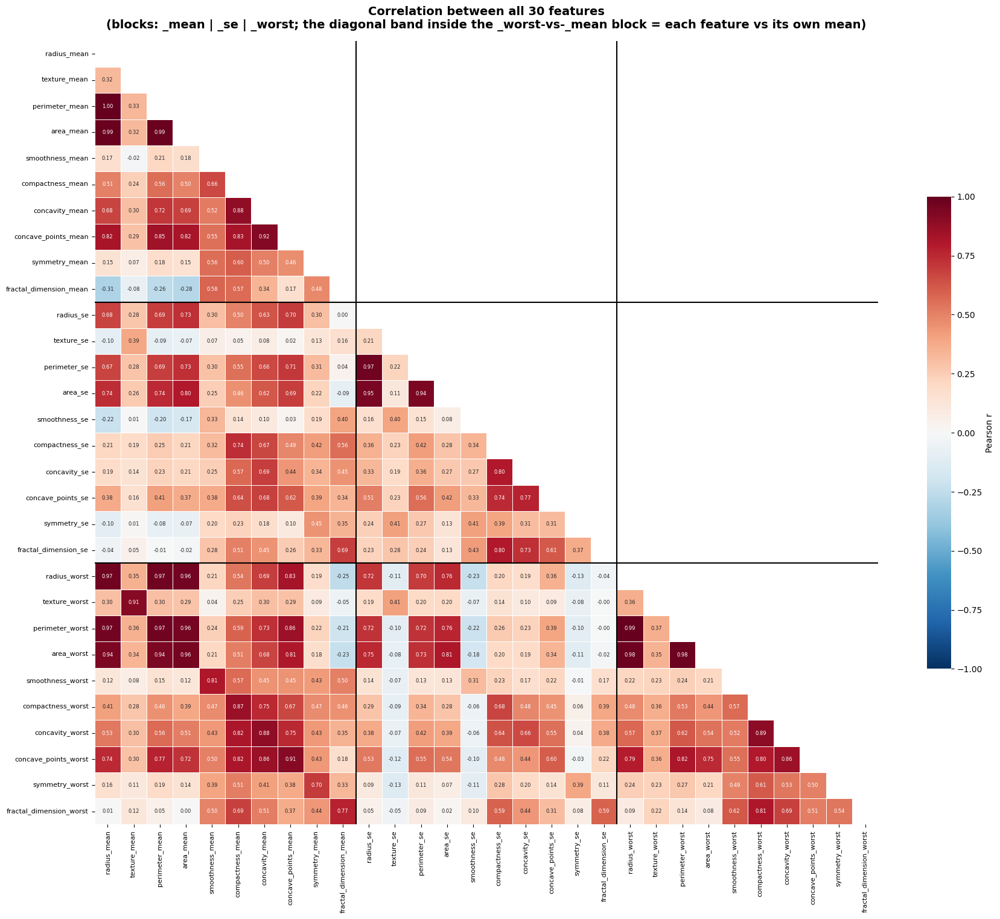

21 feature pairs with |r| > 0.9:


,feature_1,feature_2,r
0,perimeter_mean,radius_mean,0.997855
1,perimeter_worst,radius_worst,0.993708
2,area_mean,radius_mean,0.987357
3,area_mean,perimeter_mean,0.986507
4,area_worst,radius_worst,0.984015
5,area_worst,perimeter_worst,0.977578
6,perimeter_se,radius_se,0.972794
7,perimeter_worst,perimeter_mean,0.970387
8,radius_worst,radius_mean,0.969539
9,radius_worst,perimeter_mean,0.969476



Radius / perimeter / area correlations:
  _mean: radius-perimeter = 0.998, radius-area = 0.987, perimeter-area = 0.987
  _se: radius-perimeter = 0.973, radius-area = 0.952, perimeter-area = 0.938
  _worst: radius-perimeter = 0.994, radius-area = 0.984, perimeter-area = 0.978

Each feature's _mean vs _worst correlation:


,"r(mean, worst)"
perimeter,0.970
radius,0.970
area,0.959
texture,0.912
concave_points,0.910
concavity,0.884
compactness,0.866
smoothness,0.805
fractal_dimension,0.767
symmetry,0.700


In [14]:
versions = ['mean', 'se', 'worst']

# Pearson correlation between all 30 features (column order: 10 _mean, 10 _se, 10 _worst)
corr = df[feat_cols].corr()

# hide the upper triangle (it mirrors the lower one) and the diagonal (always 1)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'fontsize': 6},
            square=True, linewidths=0.4, linecolor='white',
            cbar_kws={'label': 'Pearson r', 'shrink': 0.6}, ax=ax)

# separator lines between the _mean / _se / _worst blocks
for k in [10, 20]:
    ax.axhline(k, color='black', linewidth=1.5)
    ax.axvline(k, color='black', linewidth=1.5)

ax.set_title('Correlation between all 30 features\n'
             '(blocks: _mean | _se | _worst; the diagonal band inside the _worst-vs-_mean block = each feature vs its own mean)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(fontsize=8, rotation=90)
plt.yticks(fontsize=8, rotation=0)

plt.tight_layout()
fig.savefig('plots/05_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()


# --- 1. most highly correlated pairs (|r| > 0.9) ---
pairs = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1))   # lower triangle only, no diagonal
             .stack()
             .rename('r')
             .reset_index()
             .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'}))
pairs['abs_r'] = pairs.r.abs()
high = pairs[pairs.abs_r > 0.9].sort_values('abs_r', ascending=False).drop(columns='abs_r')
print(f"{len(high)} feature pairs with |r| > 0.9:")
display(high.reset_index(drop=True))

# --- 2. radius vs perimeter vs area, for each version ---
print("\nRadius / perimeter / area correlations:")
for v in versions:
    sub = df[[f'radius_{v}', f'perimeter_{v}', f'area_{v}']].corr()
    print(f"  _{v}: radius-perimeter = {sub.iloc[0, 1]:.3f}, "
          f"radius-area = {sub.iloc[0, 2]:.3f}, perimeter-area = {sub.iloc[1, 2]:.3f}")

# --- 3. how strongly each _mean feature correlates with its own _worst version ---
mean_vs_worst = pd.Series({f: df[f'{f}_mean'].corr(df[f'{f}_worst']) for f in base},
                          name='r(mean, worst)').sort_values(ascending=False)
print("\nEach feature's _mean vs _worst correlation:")
display(mean_vs_worst.to_frame().round(3))

### Create scatterplots based on top features
**Why scatter plots:** Violin plots show one feature at a time; scatter plots show two together, revealing whether a pair separates the classes better than either alone (complementary) or just repeats the same information (redundant, e.g. radius vs perimeter). <br>
Best features are selected on the basis of **class separation** (Cohen's d from the violin plots, keeping features with d ≥ ~1.5) and **low redundancy** (from the correlation heatmap, dropping one of any pair with r > 0.9 and keeping the higher-d feature), plus one or two lower-d (d=1) features that carry different/new information (e.g. texture_worst).

##### pick the features

In [15]:
D_STRONG = 1.5      # step 1: shortlist threshold (from the violin plot)
R_DUPLICATE = 0.9   # step 2: above this, two features count as duplicates
D_EXTRA = 0.8       # step 3: minimum d for a "different information" feature
R_EXTRA = 0.6       # step 3: extra feature must correlate below this with everything already picked
MAX_STRONG, MAX_EXTRA = 3, 2

corr = df[feat_cols].corr()

# Cohen's d for all 30 features, strongest first
d = pd.Series({c: cohens_d(c) for c in feat_cols}, name='d')
d_abs = d.abs().sort_values(ascending=False)

# Step 1 + 2: walk down the ranking, keep a strong feature only if it isn't a near-duplicate of one already kept
selected = []
for f in d_abs[d_abs >= D_STRONG].index:
    if len(selected) == MAX_STRONG:
        break
    if selected and corr.loc[f, selected].abs().max() >= R_DUPLICATE:
        dup = corr.loc[f, selected].abs().idxmax()
        print(f"drop  {f:24s} d = {d[f]:5.2f}   duplicate of {dup} (r = {corr.loc[f, dup]:.2f})")
        continue
    print(f"KEEP  {f:24s} d = {d[f]:5.2f}   strong")
    selected.append(f)

# Step 3: add moderate-d features that carry different information (low correlation with everything picked)
n_extra = 0
for f in d_abs[(d_abs >= D_EXTRA) & (d_abs < D_STRONG)].index:
    if n_extra == MAX_EXTRA:
        break
    max_r = corr.loc[f, selected].abs().max()
    if max_r < R_EXTRA:
        print(f"KEEP  {f:24s} d = {d[f]:5.2f}   different information (max |r| with picked = {max_r:.2f})")
        selected.append(f)
        n_extra += 1

print("\nSelected features:", selected)
display(pd.DataFrame({'d': d[selected].round(2)}).join(corr.loc[selected, selected].round(2)))


KEEP  concave_points_worst     d =  2.69   strong
KEEP  perimeter_worst          d =  2.60   strong
drop  concave_points_mean      d =  2.55   duplicate of concave_points_worst (r = 0.91)
drop  radius_worst             d =  2.54   duplicate of perimeter_worst (r = 0.99)
drop  perimeter_mean           d =  2.29   duplicate of perimeter_worst (r = 0.97)
drop  area_worst               d =  2.23   duplicate of perimeter_worst (r = 0.98)
drop  radius_mean              d =  2.21   duplicate of perimeter_worst (r = 0.97)
drop  area_mean                d =  2.08   duplicate of perimeter_worst (r = 0.96)
KEEP  concavity_mean           d =  2.00   strong
KEEP  texture_worst            d =  1.06   different information (max |r| with picked = 0.37)
KEEP  smoothness_worst         d =  0.96   different information (max |r| with picked = 0.55)

Selected features: ['concave_points_worst', 'perimeter_worst', 'concavity_mean', 'texture_worst', 'smoothness_worst']


,d,concave_points_worst,perimeter_worst,concavity_mean,texture_worst,smoothness_worst
concave_points_worst,2.69,1.00,0.82,0.86,0.36,0.55
perimeter_worst,2.60,0.82,1.00,0.73,0.37,0.24
concavity_mean,2.00,0.86,0.73,1.00,0.30,0.45
texture_worst,1.06,0.36,0.37,0.30,1.00,0.23
smoothness_worst,0.96,0.55,0.24,0.45,0.23,1.00


create plots

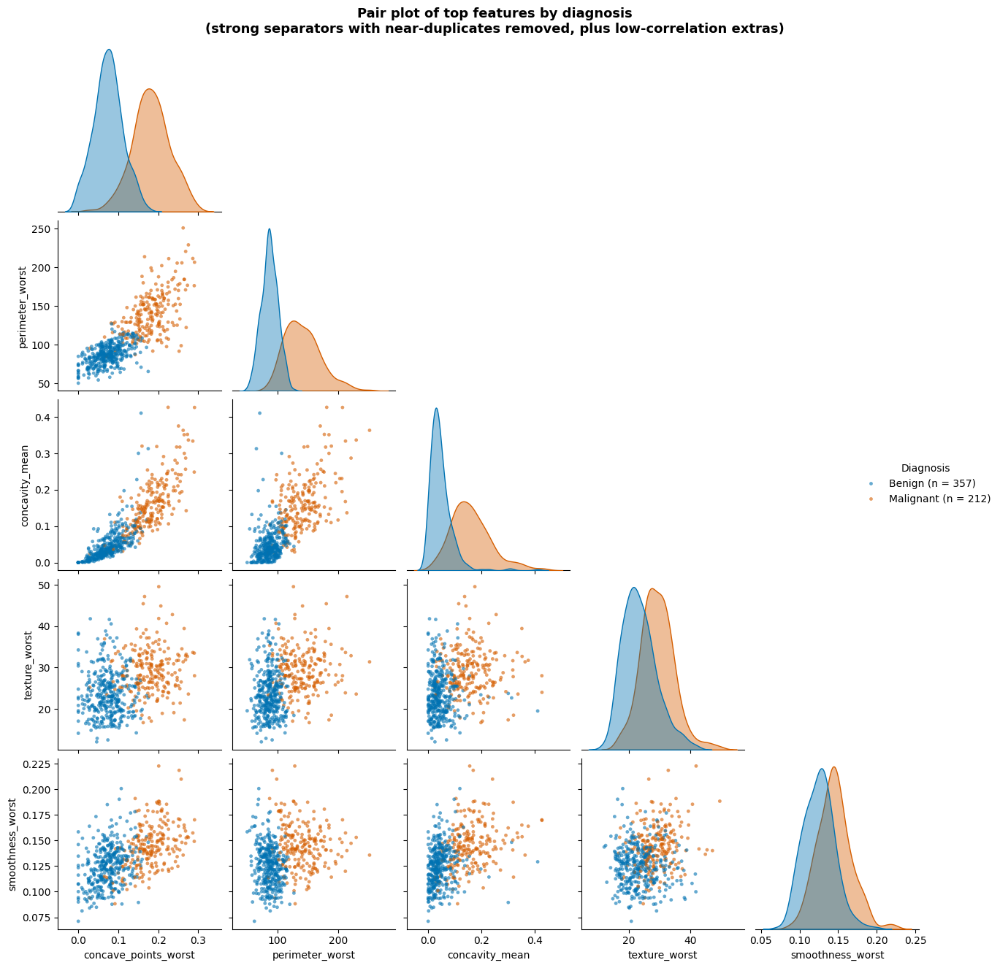

In [16]:
g = sns.pairplot(df[selected + ['diagnosis']], hue='diagnosis', hue_order=['B', 'M'], palette=colors,
                 corner=True,                       # lower triangle only; upper is a mirror
                 diag_kind='kde', diag_kws={'common_norm': False, 'fill': True, 'alpha': 0.4},
                 plot_kws={'s': 12, 'alpha': 0.6, 'edgecolor': 'none'},
                 height=2.6)

g._legend.set_title('Diagnosis')
for t in g._legend.texts:
    t.set_text(f"{labels[t.get_text()]} (n = {n[t.get_text()]})")

g.fig.suptitle('Pair plot of top features by diagnosis\n'
               '(strong separators with near-duplicates removed, plus low-correlation extras)',
               fontsize=13, fontweight='bold', y=1.02)

g.savefig('plots/06_pairplot_top_features.png', dpi=200, bbox_inches='tight')
plt.show()


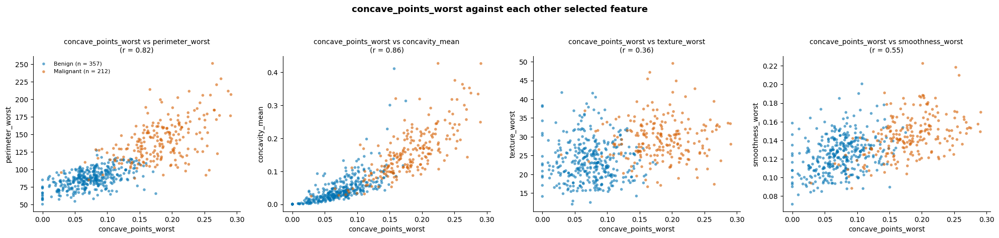

In [17]:
# the strongest feature against each of the others, so you can check whether the second feature
# separates the cases the first one gets wrong
top = selected[0]
others = selected[1:]

fig, axes = plt.subplots(1, len(others), figsize=(5 * len(others), 4.8), squeeze=False)
axes = axes[0]

for ax, f in zip(axes, others):
    for diag in ['B', 'M']:
        sub = df[df.diagnosis == diag]
        ax.scatter(sub[top], sub[f], s=16, alpha=0.6, color=colors[diag], edgecolor='none',
                   label=f'{labels[diag]} (n = {n[diag]})')
    ax.set_xlabel(top)
    ax.set_ylabel(f)
    ax.set_title(f'{top} vs {f}\n(r = {corr.loc[top, f]:.2f})', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f'{top} against each other selected feature', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig('plots/07_scatter_top_feature_pairs.png', dpi=200, bbox_inches='tight')
plt.show()


### Outliers per feature
**Why:** Outliers can distort the mean/SD, scaling and some models (e.g. logistic regression, SVM). Before removing anything, check whether the outliers are data errors or real extreme tumours. <br>
A value is counted as an outlier if it falls below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR (the same rule box-plot whiskers use). <br>
Each feature's outliers are split by diagnosis: if most outliers are malignant (well above the dataset's 37% malignant share), they are probably real large/abnormal tumours and carry useful signal, so they should **not** be removed.


Rows with at least one outlier: 171 of 569
Malignant share of the whole dataset: 37.3%  (if an outlier column is well above this, its outliers are mostly malignant cases, not errors)


,n_outliers,pct,n_benign,n_malignant,pct_malignant
area_se,65,11.4,0,65,100.0
radius_se,38,6.7,1,37,97.4
perimeter_se,38,6.7,0,38,100.0
area_worst,35,6.2,0,35,100.0
smoothness_se,30,5.3,26,4,13.3
fractal_dimension_se,28,4.9,18,10,35.7
compactness_se,28,4.9,14,14,50.0
symmetry_se,27,4.7,11,16,59.3
area_mean,25,4.4,0,25,100.0
fractal_dimension_worst,24,4.2,6,18,75.0


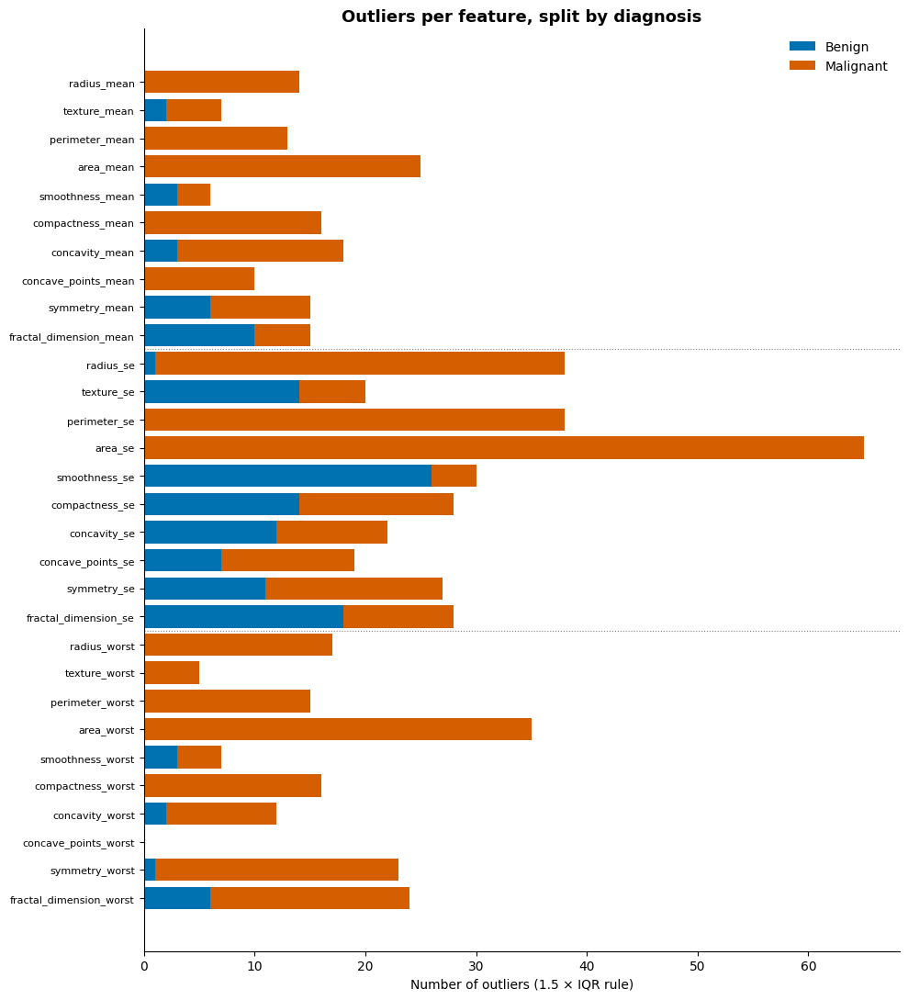

In [18]:
# a value is an outlier if it falls below Q1 - 1.5*IQR or above Q3 + 1.5*IQR (the box-plot whisker rule)
q1 = df[feat_cols].quantile(0.25)
q3 = df[feat_cols].quantile(0.75)
iqr = q3 - q1
is_out = (df[feat_cols] < q1 - 1.5 * iqr) | (df[feat_cols] > q3 + 1.5 * iqr)

outliers = pd.DataFrame({
    'n_outliers':  is_out.sum(),
    'pct':         (is_out.mean() * 100).round(1),
    'n_benign':    is_out[df.diagnosis == 'B'].sum(),
    'n_malignant': is_out[df.diagnosis == 'M'].sum(),
})
outliers['pct_malignant'] = (outliers.n_malignant / outliers.n_outliers * 100).round(1)

print(f"Rows with at least one outlier: {is_out.any(axis=1).sum()} of {len(df)}")
print(f"Malignant share of the whole dataset: {n['M'] / len(df) * 100:.1f}%  "
      f"(if an outlier column is well above this, its outliers are mostly malignant cases, not errors)")
display(outliers.sort_values('n_outliers', ascending=False))

# stacked bars: how many outliers per feature, split by diagnosis
fig, ax = plt.subplots(figsize=(10, 11))
y = np.arange(len(feat_cols))[::-1]   # first feature at the top
ax.barh(y, outliers.n_benign, color=colors['B'], label=labels['B'])
ax.barh(y, outliers.n_malignant, left=outliers.n_benign, color=colors['M'], label=labels['M'])

for k in [10, 20]:   # separators between the _mean / _se / _worst blocks
    ax.axhline(len(feat_cols) - k - 0.5, color='grey', linewidth=0.8, linestyle=':')

ax.set_yticks(y)
ax.set_yticklabels(feat_cols, fontsize=8)
ax.set_xlabel('Number of outliers (1.5 × IQR rule)')
ax.set_title('Outliers per feature, split by diagnosis', fontsize=13, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig('plots/08_outliers_iqr_by_feature.png', dpi=200, bbox_inches='tight')
plt.show()


Compare the mean, SE and worst versions of each measurement

,mean,se,worst,best_version
concave_points,2.55,0.92,2.69,worst
perimeter,2.29,1.38,2.60,worst
radius,2.21,1.42,2.54,worst
area,2.08,1.35,2.23,worst
concavity,2.00,0.54,1.81,mean
compactness,1.53,0.63,1.51,mean
texture,0.94,-0.02,1.06,worst
smoothness,0.79,-0.14,0.96,worst
symmetry,0.72,-0.01,0.95,worst
fractal_dimension,-0.03,0.16,0.71,worst


Best version count: {'worst': 8, 'mean': 2}


/tmp/ipykernel_59674/2629461273.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, title='Version')


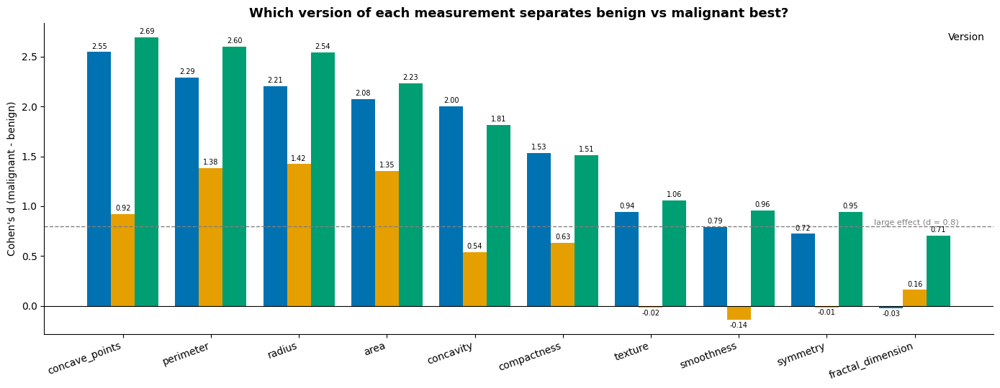

In [19]:
version_colors = {'mean': '#0072B2', 'se': '#E69F00', 'worst': '#009E73'}   # same as plot 01

# Cohen's d for every measurement x version
d_table = pd.DataFrame({v: [cohens_d(f'{f}_{v}') for f in base] for v in versions}, index=base)
d_table['best_version'] = d_table[versions].abs().idxmax(axis=1)

# order measurements by their best |d|
order_v = d_table[versions].abs().max(axis=1).sort_values(ascending=False).index
d_table = d_table.loc[order_v]

display(d_table.round(2))
print("Best version count:", d_table.best_version.value_counts().to_dict())

# grouped bars: one group per measurement, one bar per version
fig, ax = plt.subplots(figsize=(14, 5.5))
x = np.arange(len(order_v))
width = 0.27

for k, v in enumerate(versions):
    vals = d_table[v]
    bars = ax.bar(x + (k - 1) * width, vals, width, color=version_colors[v], label=f'_{v}')
    ax.bar_label(bars, labels=[f'{val:.2f}' for val in vals], fontsize=7, padding=2)

ax.axhline(0.8, color='grey', linewidth=1, linestyle='--')
ax.text(len(order_v) - 0.5, 0.8, 'large effect (d = 0.8)', ha='right', va='bottom', fontsize=8, color='grey')
ax.axhline(0, color='black', linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(order_v, rotation=20, ha='right')
ax.set_ylabel("Cohen's d (malignant - benign)")
ax.set_title('Which version of each measurement separates benign vs malignant best?',
             fontsize=13, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, title='Version')

plt.tight_layout()
fig.savefig('plots/09_mean_vs_se_vs_worst_cohens_d.png', dpi=200, bbox_inches='tight')
plt.show()


PCA

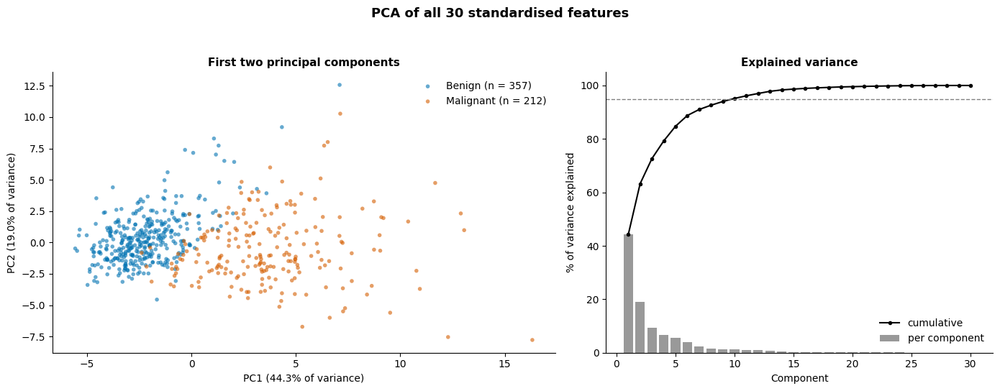

PC1 + PC2 explain 63.2% of the variance; 10 components are needed for 95%.

Top 8 features by |loading| on each component:
  PC1: concave_points_mean (+0.26), concavity_mean (+0.26), concave_points_worst (+0.25), compactness_mean (+0.24), perimeter_worst (+0.24), concavity_worst (+0.23), radius_worst (+0.23), perimeter_mean (+0.23)
  PC2: fractal_dimension_mean (+0.37), fractal_dimension_se (+0.28), fractal_dimension_worst (+0.28), radius_mean (-0.23), compactness_se (+0.23), area_mean (-0.23), radius_worst (-0.22), area_worst (-0.22)


In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# standardise first, otherwise area (~1000s) would dominate every component
X = StandardScaler().fit_transform(df[feat_cols])
pca = PCA().fit(X)
pcs = pca.transform(X)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})

# left: first two components coloured by diagnosis
ax = axes[0]
for diag in ['B', 'M']:
    mask = (df.diagnosis == diag).values
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=16, alpha=0.6, color=colors[diag], edgecolor='none',
               label=f'{labels[diag]} (n = {n[diag]})')
ax.set_xlabel(f'PC1 ({ev[0] * 100:.1f}% of variance)')
ax.set_ylabel(f'PC2 ({ev[1] * 100:.1f}% of variance)')
ax.set_title('First two principal components', fontsize=11, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

# right: how much variance each component explains (scree + cumulative)
ax = axes[1]
k = np.arange(1, len(ev) + 1)
ax.bar(k, ev * 100, color='#999999', label='per component')
ax.plot(k, np.cumsum(ev) * 100, color='black', marker='o', markersize=3, label='cumulative')
ax.axhline(95, color='grey', linewidth=1, linestyle='--')
ax.set_xlabel('Component')
ax.set_ylabel('% of variance explained')
ax.set_title('Explained variance', fontsize=11, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)

fig.suptitle('PCA of all 30 standardised features', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig('plots/10_pca_first_two_components.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"PC1 + PC2 explain {ev[:2].sum() * 100:.1f}% of the variance; "
      f"{np.argmax(np.cumsum(ev) >= 0.95) + 1} components are needed for 95%.")

# which features drive each component
loadings = pd.DataFrame(pca.components_[:2].T, index=feat_cols, columns=['PC1', 'PC2'])
print("\nTop 8 features by |loading| on each component:")
for pc in ['PC1', 'PC2']:
    top8 = loadings[pc].abs().sort_values(ascending=False).head(8).index
    print(f"  {pc}: " + ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in top8))


Download the plots locally

In [21]:
plot_files = sorted(f for f in os.listdir('plots') if f.lower().endswith(('.png', '.jpg', '.jpeg', '.svg')))

listing = pd.DataFrame({
    'file':     plot_files,
    'size_KB':  [round(os.path.getsize(f'plots/{f}') / 1024) for f in plot_files],
    'modified': [pd.Timestamp.fromtimestamp(os.path.getmtime(f'plots/{f}')).strftime('%Y-%m-%d %H:%M')
                 for f in plot_files],
})

print(f"{len(plot_files)} plots in {os.path.abspath('plots')}")
display(listing)


12 plots in /content/plots


,file,size_KB,modified
0,01_all_features.png,794,2026-10-31 17:48
1,02_benign_vs_malignant.png,1002,2026-10-31 16:00
2,02_counts_benign_vs_malignant.png,996,2026-10-31 16:02
3,02_density_benign_vs_malignant.png,1003,2026-10-31 17:48
4,03_counts_benign_vs_malignant.png,973,2026-10-31 17:48
5,04_violin_benign_vs_malignant.png,546,2026-10-31 17:48
6,05_correlation_heatmap.png,659,2026-10-31 17:49
7,06_pairplot_top_features.png,950,2026-10-31 17:49
8,07_scatter_top_feature_pairs.png,565,2026-10-31 17:49
9,08_outliers_iqr_by_feature.png,161,2026-10-31 17:53


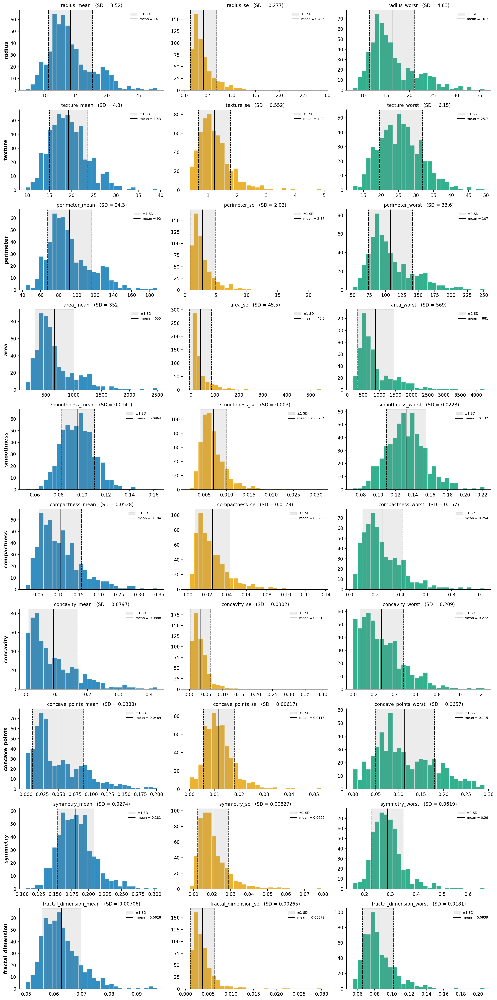

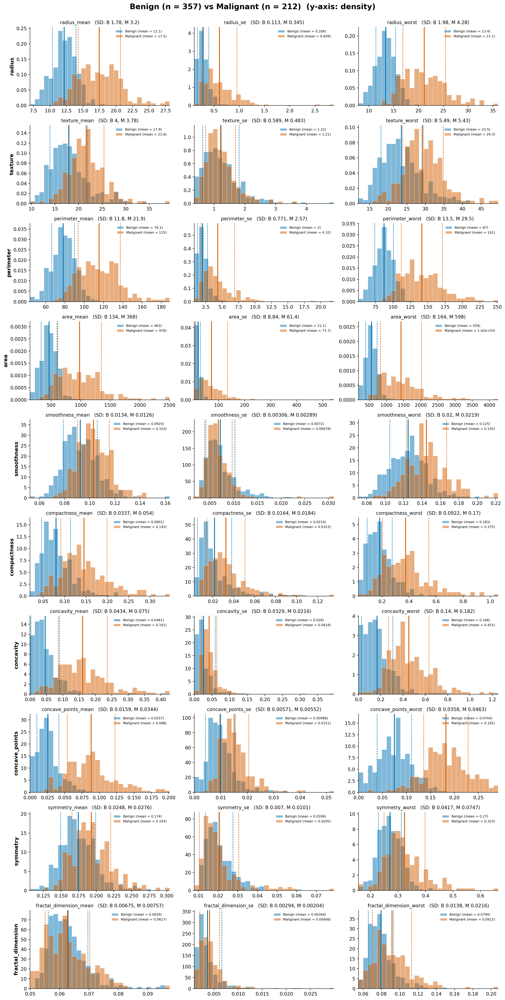

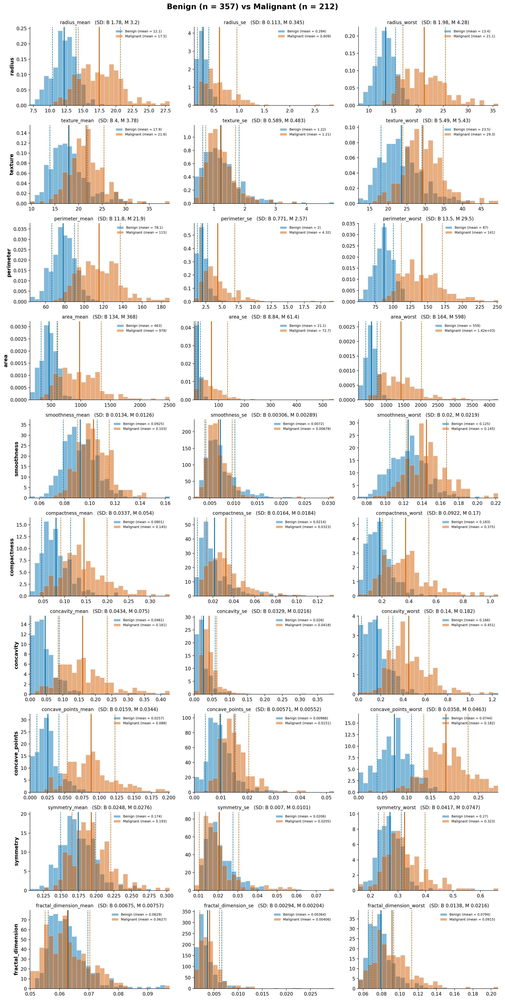

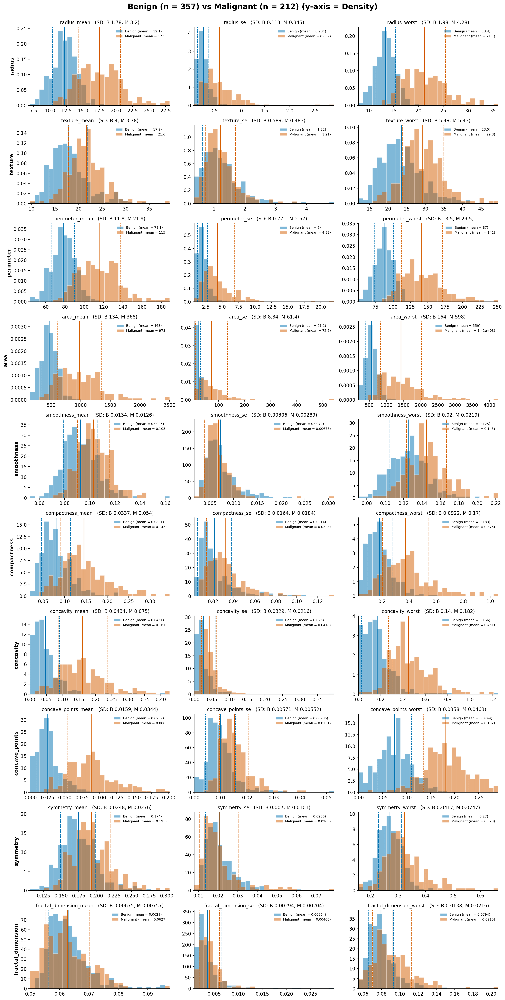

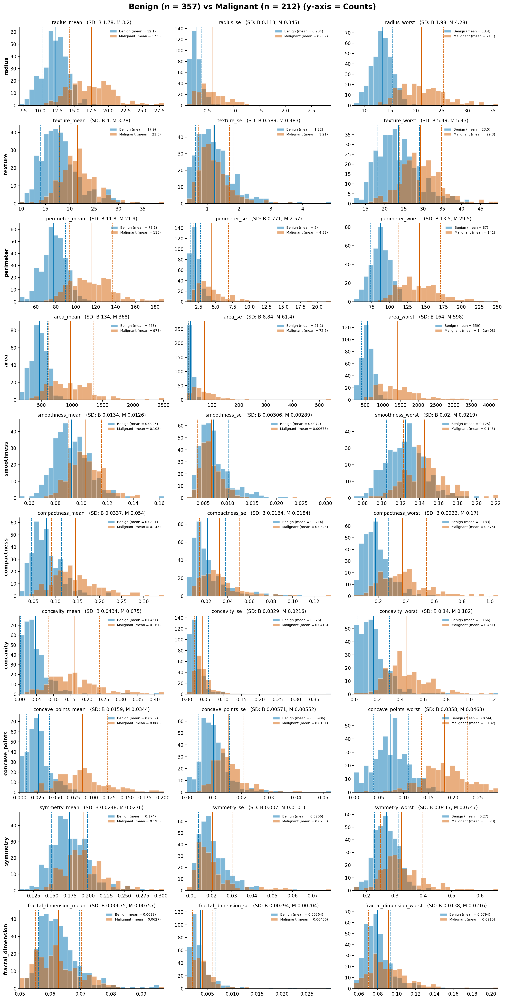

...

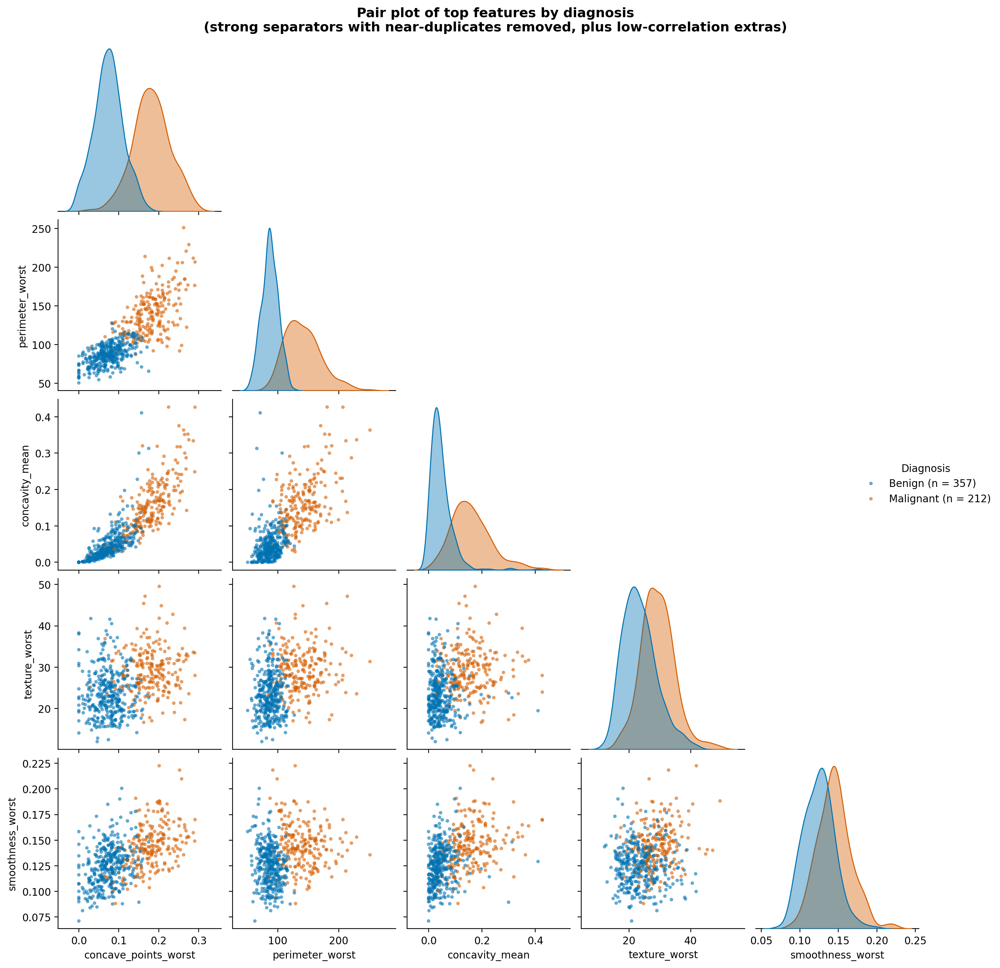

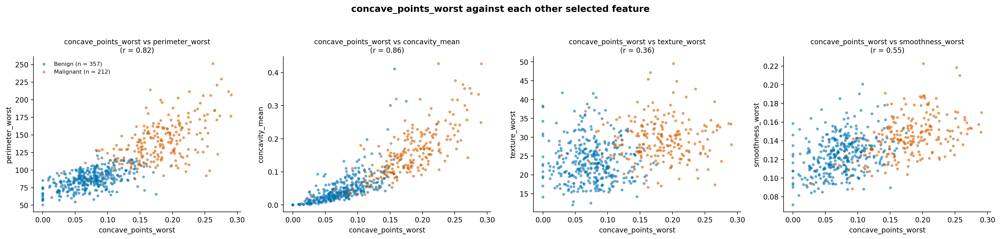

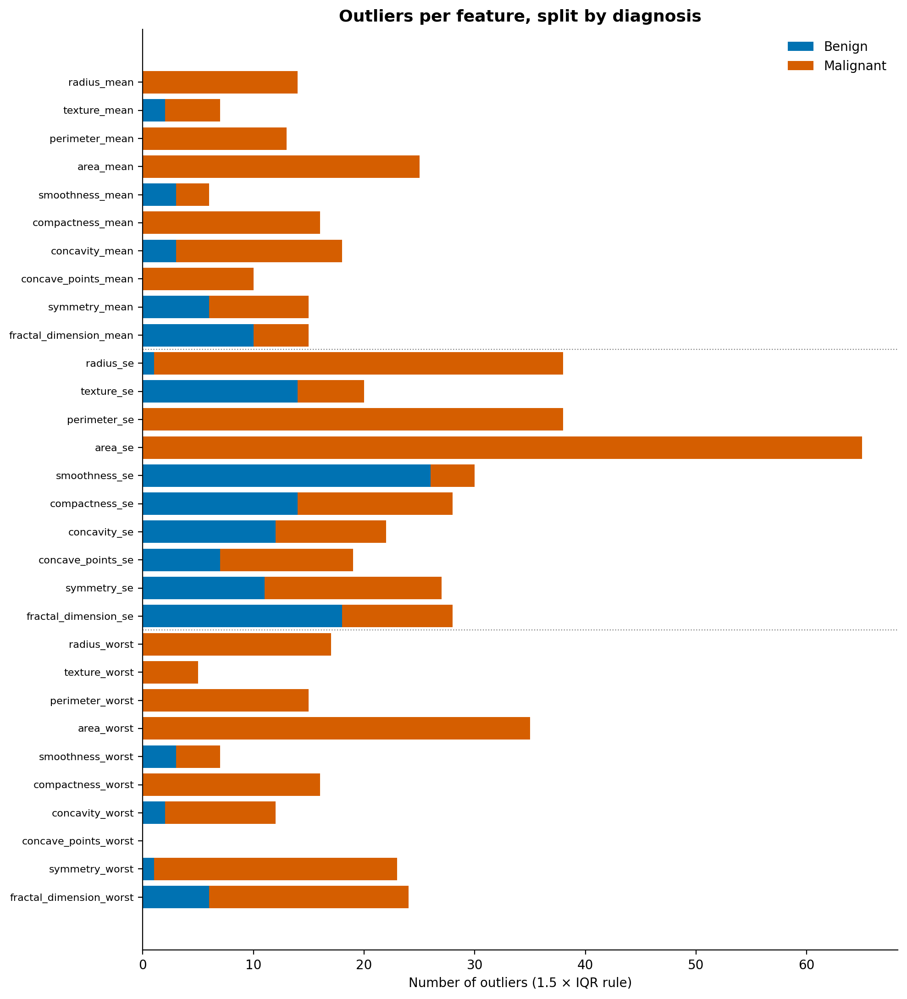

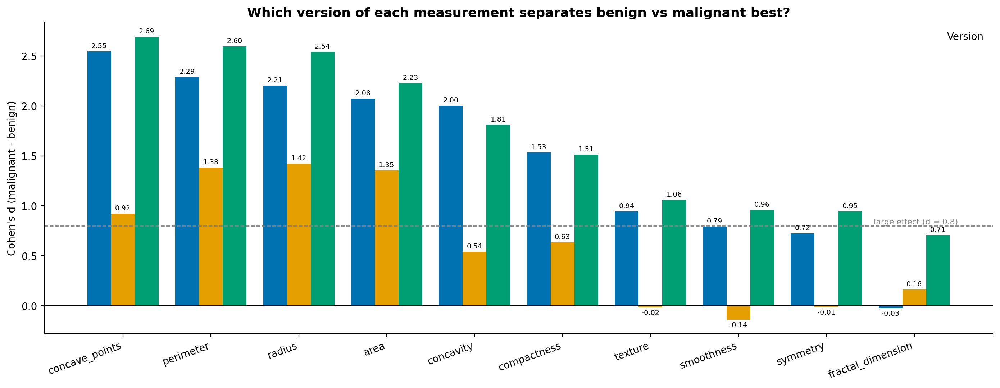

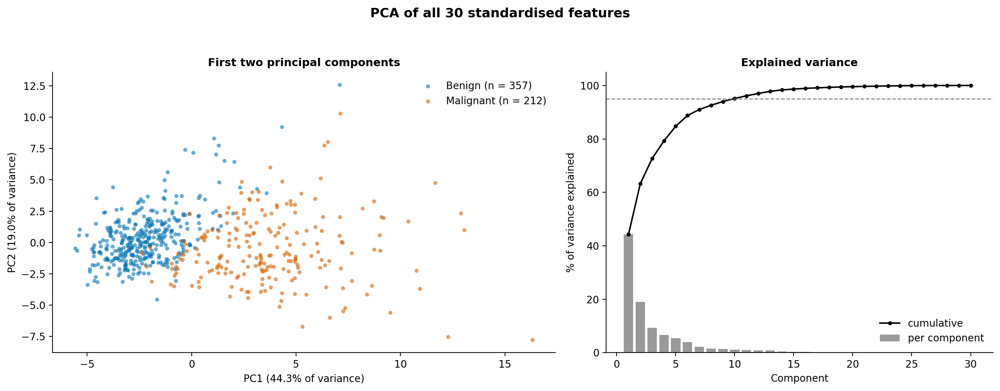

In [22]:
from IPython.display import Image

for f in plot_files:
    display(HTML(f"<h4>{f}</h4>"))
    display(Image(filename=f'plots/{f}', width=900))


In [23]:
for folder in ['plots', '.']:
    files_here = sorted(f for f in os.listdir(folder) if os.path.isfile(os.path.join(folder, f)))

    listing = pd.DataFrame({
        'file':     files_here,
        'size_KB':  [round(os.path.getsize(os.path.join(folder, f)) / 1024) for f in files_here],
        'modified': [pd.Timestamp.fromtimestamp(os.path.getmtime(os.path.join(folder, f))).strftime('%Y-%m-%d %H:%M')
                     for f in files_here],
    })

    print(f"\n{len(files_here)} files in {os.path.abspath(folder)}")
    display(listing)



12 files in /content/plots


,file,size_KB,modified
0,01_all_features.png,794,2026-10-31 17:48
1,02_benign_vs_malignant.png,1002,2026-10-31 16:00
2,02_counts_benign_vs_malignant.png,996,2026-10-31 16:02
3,02_density_benign_vs_malignant.png,1003,2026-10-31 17:48
4,03_counts_benign_vs_malignant.png,973,2026-10-31 17:48
5,04_violin_benign_vs_malignant.png,546,2026-10-31 17:48
6,05_correlation_heatmap.png,659,2026-10-31 17:49
7,06_pairplot_top_features.png,950,2026-10-31 17:49
8,07_scatter_top_feature_pairs.png,565,2026-10-31 17:49
9,08_outliers_iqr_by_feature.png,161,2026-10-31 17:53



4 files in /content


,file,size_KB,modified
0,dataset_prototype.zip,50,2026-10-31 10:12
1,dataset_prototype_feature_sd.csv,1,2026-10-31 14:00
2,dataset_prototype_feature_sd_by_diagnosis.csv,1,2026-10-31 14:15
3,dataset_summary.csv,3,2026-10-31 17:48


Below steps are for cleaning up the plots folder only

In [24]:
to_delete = ['02_benign_vs_malignant.png', '02_density_benign_vs_malignant.png']

for f in to_delete:
    path = os.path.join('plots', f)
    if os.path.exists(path):
        os.remove(path)
        print(f"deleted  {path}")
    else:
        print(f"not found  {path}")

print("\nRemaining in plots/:", sorted(os.listdir('plots')))


deleted  plots/02_benign_vs_malignant.png
deleted  plots/02_density_benign_vs_malignant.png

Remaining in plots/: ['01_all_features.png', '02_counts_benign_vs_malignant.png', '03_counts_benign_vs_malignant.png', '04_violin_benign_vs_malignant.png', '05_correlation_heatmap.png', '06_pairplot_top_features.png', '07_scatter_top_feature_pairs.png', '08_outliers_iqr_by_feature.png', '09_mean_vs_se_vs_worst_cohens_d.png', '10_pca_first_two_components.png']


In [25]:
# everything the notebook creates: the plots folder + output files
outputs = ['plots', 'dataset_summary.csv']

with zipfile.ZipFile('outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for item in outputs:
        if os.path.isdir(item):
            for f in sorted(os.listdir(item)):
                z.write(os.path.join(item, f))       # keeps the plots/ folder structure
        elif os.path.exists(item):
            z.write(item)
        else:
            print(f"not found, skipped: {item}")
    print("Zipped:", z.namelist())

files.download('outputs.zip')


Zipped: ['plots/01_all_features.png', 'plots/02_counts_benign_vs_malignant.png', 'plots/03_counts_benign_vs_malignant.png', 'plots/04_violin_benign_vs_malignant.png', 'plots/05_correlation_heatmap.png', 'plots/06_pairplot_top_features.png', 'plots/07_scatter_top_feature_pairs.png', 'plots/08_outliers_iqr_by_feature.png', 'plots/09_mean_vs_se_vs_worst_cohens_d.png', 'plots/10_pca_first_two_components.png', 'dataset_summary.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download the created plots and .csv files locally. Currently they are saved in the colab storage